# Hierarchical clustering applied to countries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scipy.cluster.hierarchy as shc
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize, StandardScaler

Indicators of 164 countries, from the World Happiness Report (Gallup World Poll).

| Variable | Description |
|---|---|
| `Ladder` | life evaluation, from 0 (worst possible life) to 10 (best possible life) |
| `Log_GDP` | logarithm of the GDP per capita |
| `Soc_Support` | social support: proportion with someone to count on in times of trouble |
| `Health_Expect` | healthy life expectancy at birth (years) |
| `Freedom` | proportion satisfied with the freedom to make life choices |
| `Generosity` | donations to charity, adjusted by GDP |
| `Conf_Gov` | proportion with confidence in the national government |
| `Pos_Affect`, `Neg_Affect` | proportions that felt positive and negative emotions the previous day |
| `Corrupt` | perception of corruption |
| `sdLadder`, `cvLadder` | standard deviation and coefficient of variation of the life evaluation within the country |
| `Gini_Household` | Gini index of the household income |
| `Int_Score` | an additional score in the file, on a 0 to 10 scale |

In [2]:
data = pd.read_csv('countries.csv')
data.head()

,Country,Ladder,Log_GDP,Soc_Support,Health_Expect,Freedom,Generosity,Conf_Gov,Pos_Affect,Neg_Affect,Corrupt,sdLadder,cvLadder,Gini_Household,Int_Score
0,Afghanistan,4.220169,7.497288,0.559072,49.871265,0.522566,0.057393,0.324990,0.564953,0.348332,0.793246,1.796219,0.425627,0.509206,1.712036
1,Albania,4.511101,9.282300,0.638411,68.698380,0.729819,-0.017927,0.400910,0.675244,0.321706,0.901071,2.646668,0.586701,0.416540,3.828812
2,Algeria,5.388171,9.549138,0.748150,64.829948,0.713054,-0.034407,0.406998,0.668838,0.371372,0.769240,2.109472,0.391501,0.611013,4.400735
3,Angola,3.794838,8.847354,0.754615,45.092995,0.374542,-0.164495,0.572346,0.578517,0.367864,0.834076,2.196711,0.578868,0.440699,1.375906
4,Argentina,6.427221,10.146652,0.882819,67.443993,0.847702,-0.034153,0.419562,0.841907,0.311646,0.850924,2.127109,0.330953,0.332071,7.344209


In [3]:
country_names = data['Country']
country_names = country_names.tolist()

data = data.drop('Country', axis=1)

data_scaled = normalize(data)
data_scaled = pd.DataFrame(data_scaled, columns=data.columns)
data_scaled.head()

,Ladder,Log_GDP,Soc_Support,Health_Expect,Freedom,Generosity,Conf_Gov,Pos_Affect,Neg_Affect,Corrupt,sdLadder,cvLadder,Gini_Household,Int_Score
0,0.083254,0.147903,0.011029,0.983839,0.010309,0.001132,0.006411,0.011145,0.006872,0.015649,0.035435,0.008397,0.010045,0.033774
1,0.064771,0.133277,0.009166,0.986387,0.010479,-0.000257,0.005756,0.009695,0.004619,0.012938,0.038001,0.008424,0.005981,0.054975
2,0.081696,0.144785,0.011344,0.982961,0.010811,-0.000522,0.006171,0.010141,0.005631,0.011663,0.031984,0.005936,0.009264,0.066725
3,0.082118,0.191452,0.016329,0.975789,0.008105,-0.003560,0.012385,0.012519,0.007960,0.018049,0.047536,0.012526,0.009536,0.029774
4,0.093208,0.147148,0.012803,0.978082,0.012293,-0.000495,0.006085,0.012209,0.004520,0.012340,0.030848,0.004800,0.004816,0.106507


In [4]:
palette = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#56B4E9', '#D55E00', '#B8A800']

def cut_height(Z, n_clusters):
    # A height between the merge that leaves n_clusters clusters and the next one
    return (Z[-n_clusters, 2] + Z[-n_clusters+1, 2])/2

def plot_dendrogram(ax, Z, n_clusters=None, title='', labels=None, font_size=8, **kwargs):
    # Dendrogram, with the clusters in colors and the cut drawn if n_clusters is given
    shc.set_link_color_palette(palette)
    threshold = cut_height(Z, n_clusters) if n_clusters else 0
    horizontal = labels is not None
    shc.dendrogram(Z, ax=ax, labels=labels, no_labels=labels is None, leaf_font_size=font_size,
                   orientation='right' if horizontal else 'top',
                   color_threshold=threshold, above_threshold_color='#555555', **kwargs)
    if n_clusters:
        (ax.axvline if horizontal else ax.axhline)(threshold, ls='--', color='#c1121f', lw=1.5)
    (ax.set_xlabel if horizontal else ax.set_ylabel)('Distance between the merged clusters')
    ax.set_title(title)
    ax.grid(True, axis='x' if horizontal else 'y', alpha=0.25)

def ordered_clusters(Z, n_clusters):
    # Cluster of each observation, numbered in the order of the dendrogram (to match its colors)
    labels = shc.fcluster(Z, n_clusters, criterion='maxclust')
    leaves = shc.leaves_list(Z)
    order = pd.unique(labels[leaves])
    return np.array([np.where(order == label)[0][0] for label in labels])

## The four linkages

With 164 countries the names do not fit in a small dendrogram; here we look only at the shape of the trees.

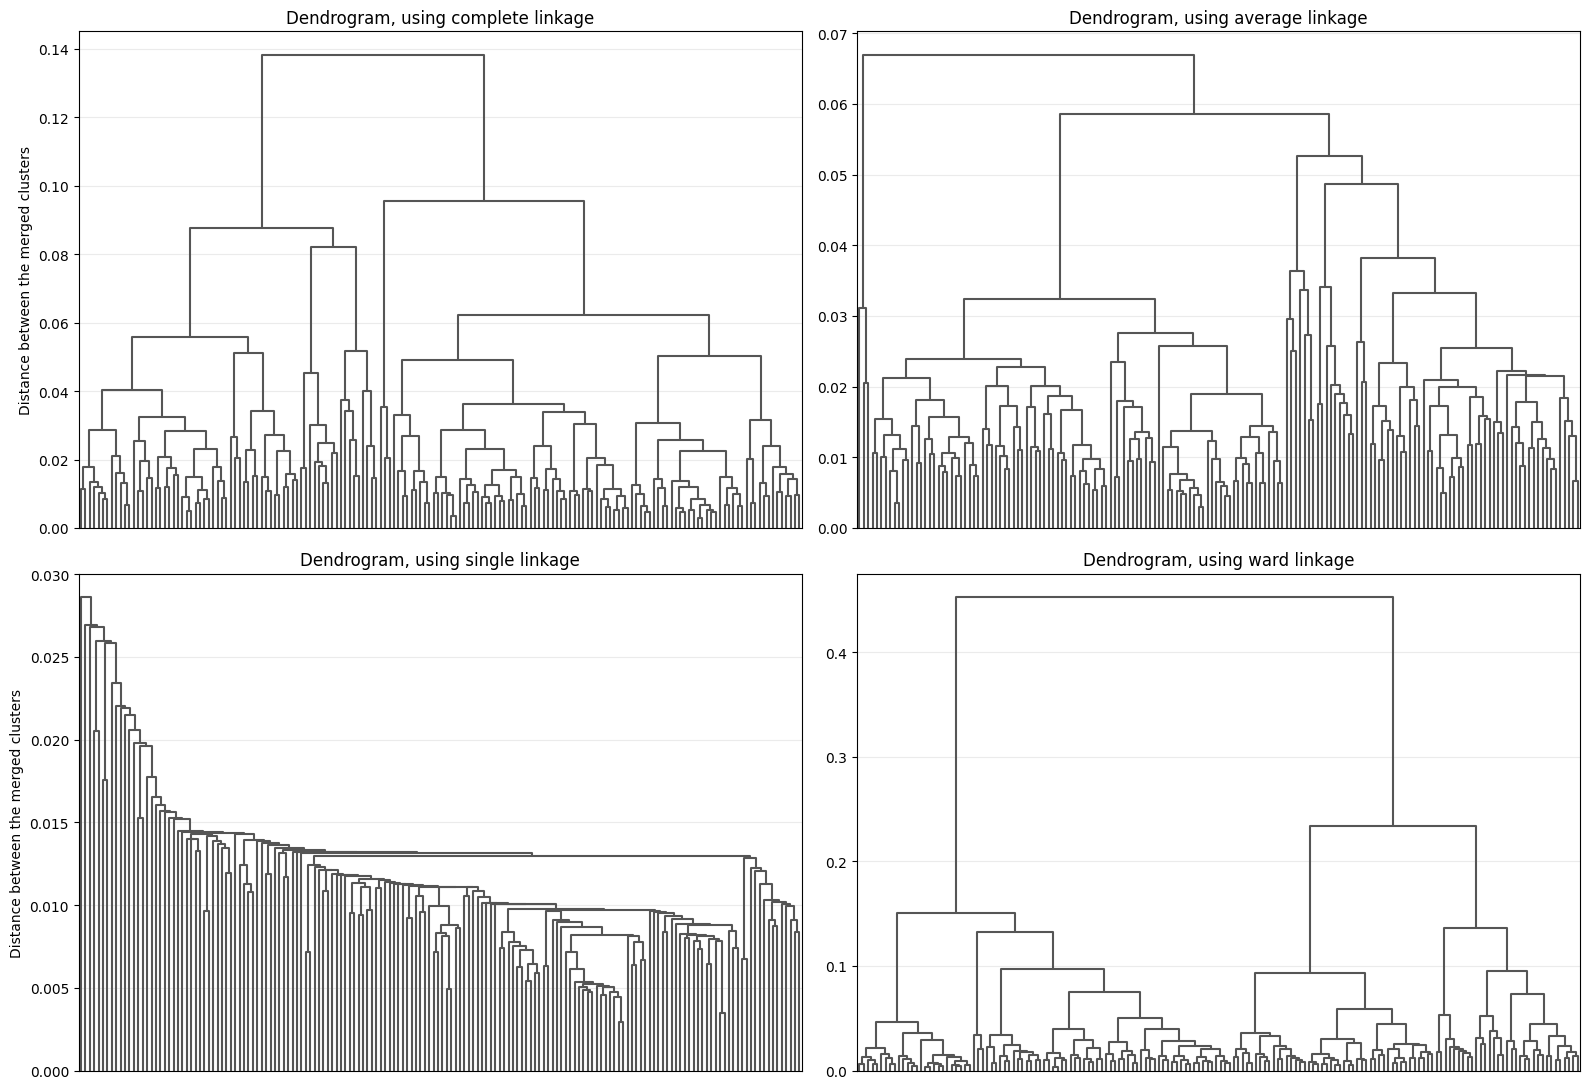

In [5]:
linkages = {method: shc.linkage(data_scaled, method=method) for method in ['complete', 'average', 'single', 'ward']}

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, (method, Z) in zip(axes.ravel(), linkages.items()):
    plot_dendrogram(ax, Z, title=f'Dendrogram, using {method} linkage')
for ax in axes[:, 1]:
    ax.set_ylabel('')
plt.tight_layout()

## Dendrogram with Ward linkage

The full dendrogram, with the names of the countries, cut in four clusters.

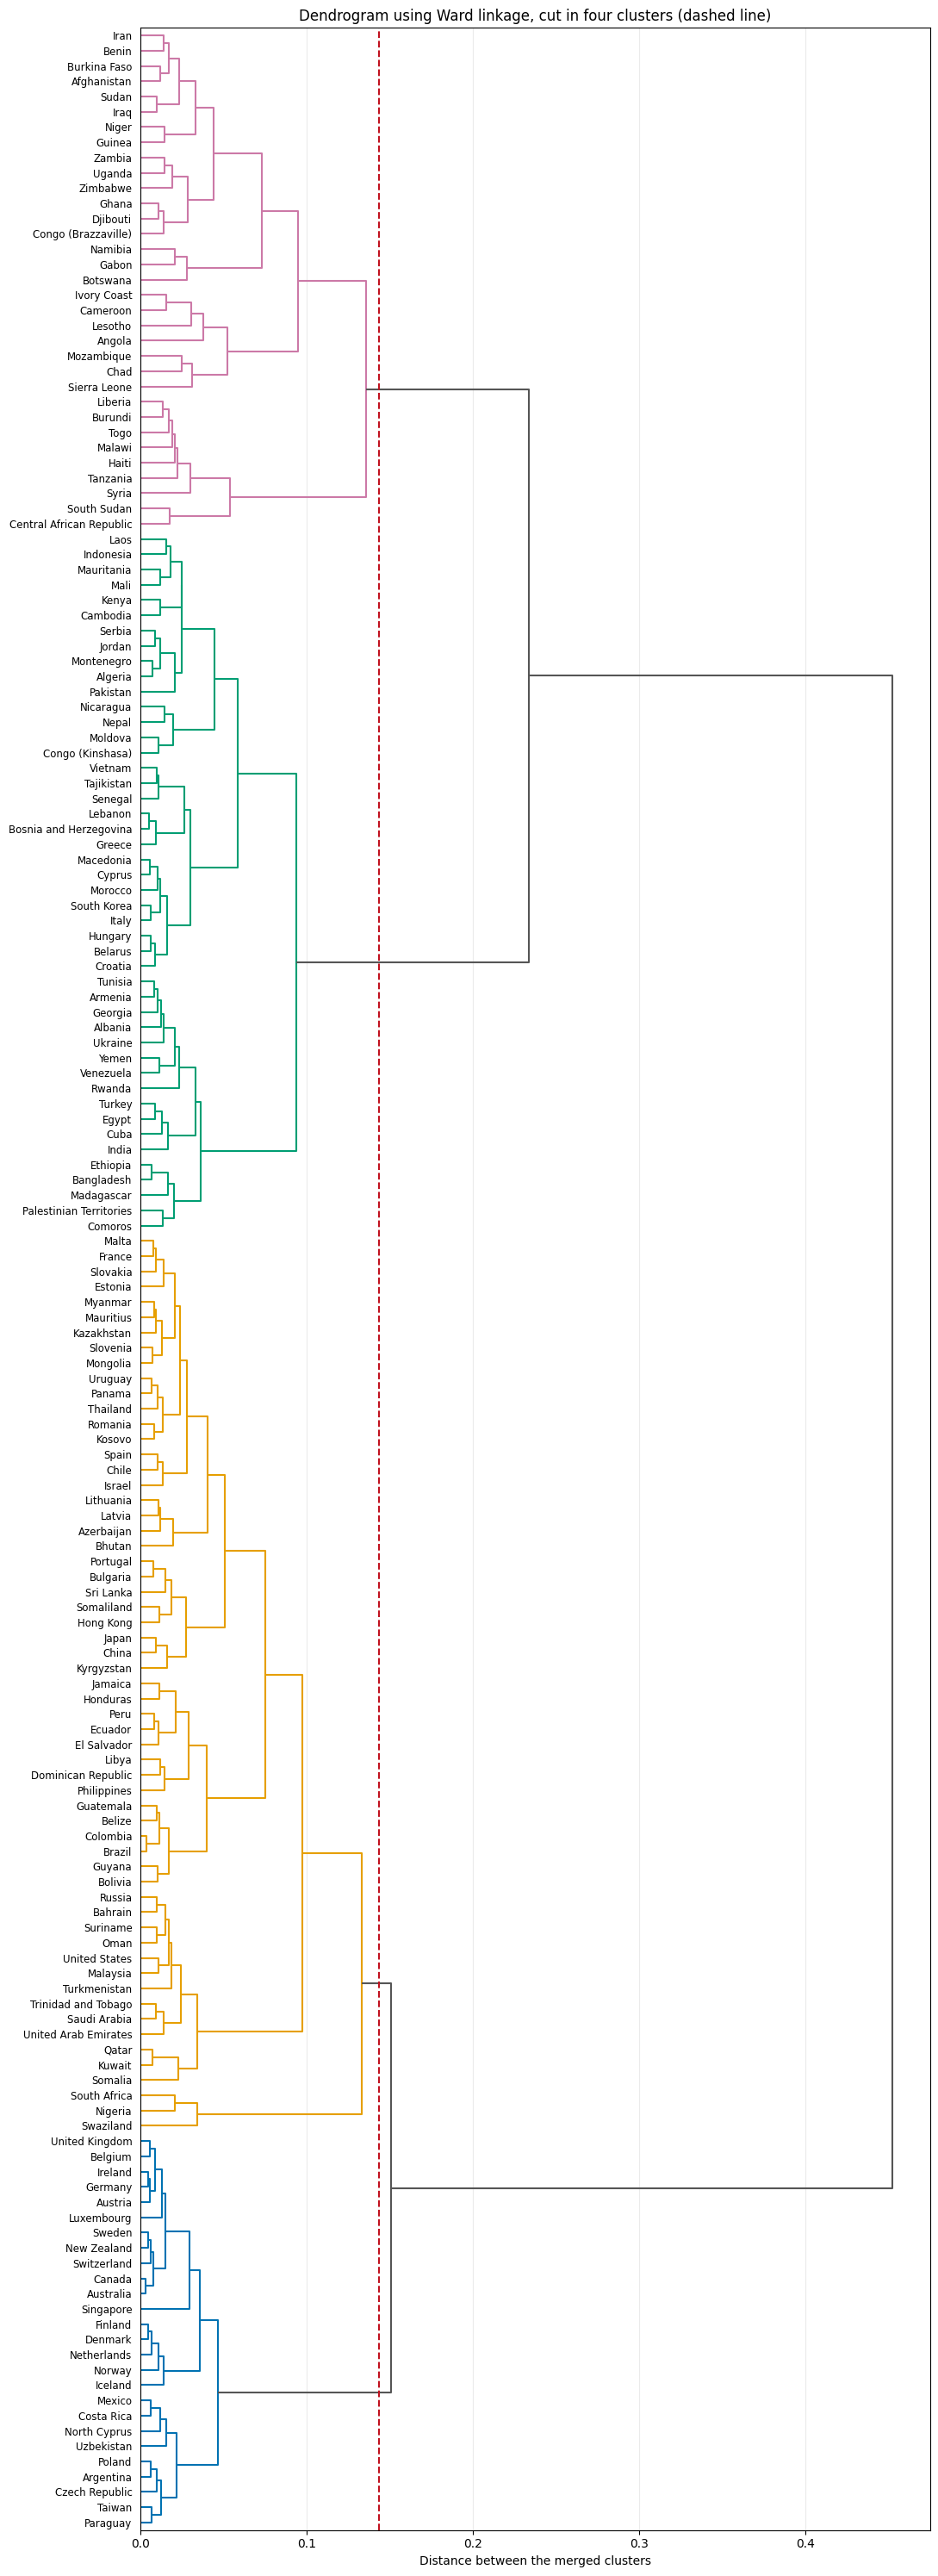

In [6]:
Z = linkages['ward']
n_clusters = 4

fig, ax = plt.subplots(figsize=(11, 30))
plot_dendrogram(ax, Z, n_clusters, 'Dendrogram using Ward linkage, cut in four clusters (dashed line)',
                labels=country_names, font_size=8.5)
plt.tight_layout()

In [7]:
cluster_labels = ordered_clusters(Z, n_clusters)
profiles = data.groupby(cluster_labels).mean()
profiles.insert(0, 'countries', pd.Series(cluster_labels).value_counts().sort_index())
profiles.round(2)

,countries,Ladder,Log_GDP,Soc_Support,Health_Expect,Freedom,Generosity,Conf_Gov,Pos_Affect,Neg_Affect,Corrupt,sdLadder,cvLadder,Gini_Household,Int_Score
0,26,6.90,10.38,0.93,69.89,0.88,0.07,0.49,0.81,0.21,0.51,1.73,0.25,0.41,8.08
1,59,5.81,9.77,0.86,64.35,0.81,-0.02,0.44,0.75,0.26,0.76,2.14,0.37,0.45,6.06
2,46,4.88,8.84,0.79,62.68,0.67,-0.02,0.41,0.66,0.30,0.79,2.10,0.43,0.42,4.17
3,33,3.97,7.89,0.64,51.73,0.67,0.00,0.59,0.63,0.38,0.79,2.56,0.66,0.58,1.84


## What `normalize` does here

`normalize` divides each **row** by its norm. In these data the healthy life expectancy takes values around 60, while most of the other variables are between 0 and 10: the norm of each row is practically its life expectancy, and after normalizing, the life expectancy of every country is close to 1.

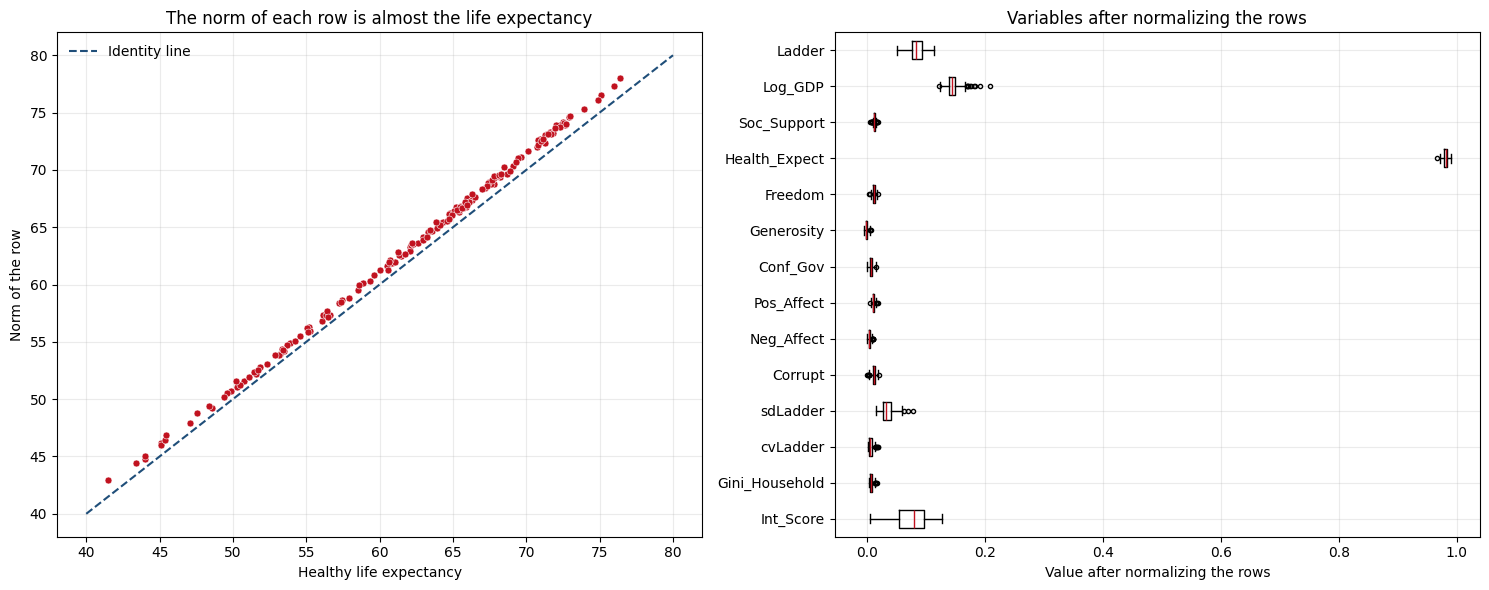

In [8]:
norms = np.sqrt((data**2).sum(axis=1))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].plot(data['Health_Expect'], norms, 'o', color='#c1121f', markersize=5, markeredgecolor='white', markeredgewidth=0.4)
axes[0].plot([40, 80], [40, 80], '--', color='#1f4e79', lw=1.5, label='Identity line')
axes[0].set_xlabel('Healthy life expectancy')
axes[0].set_ylabel('Norm of the row')
axes[0].set_title('The norm of each row is almost the life expectancy')
axes[0].legend(loc='upper left', frameon=False)

axes[1].boxplot([data_scaled[column] for column in data.columns], orientation='horizontal', tick_labels=data.columns,
                flierprops=dict(markersize=3), medianprops=dict(color='#c1121f'))
axes[1].invert_yaxis()
axes[1].set_xlabel('Value after normalizing the rows')
axes[1].set_title('Variables after normalizing the rows')
for ax in axes:
    ax.grid(True, alpha=0.25)
plt.tight_layout()

So the clusters above compare each variable *relative to the life expectancy* of the country, and the variables with large values (`Ladder`, `Log_GDP`, `Int_Score`) dominate the distances.

## Standardizing the variables

The usual alternative is to standardize each **column** (mean zero and standard deviation one), so that all the variables have the same weight in the distances.

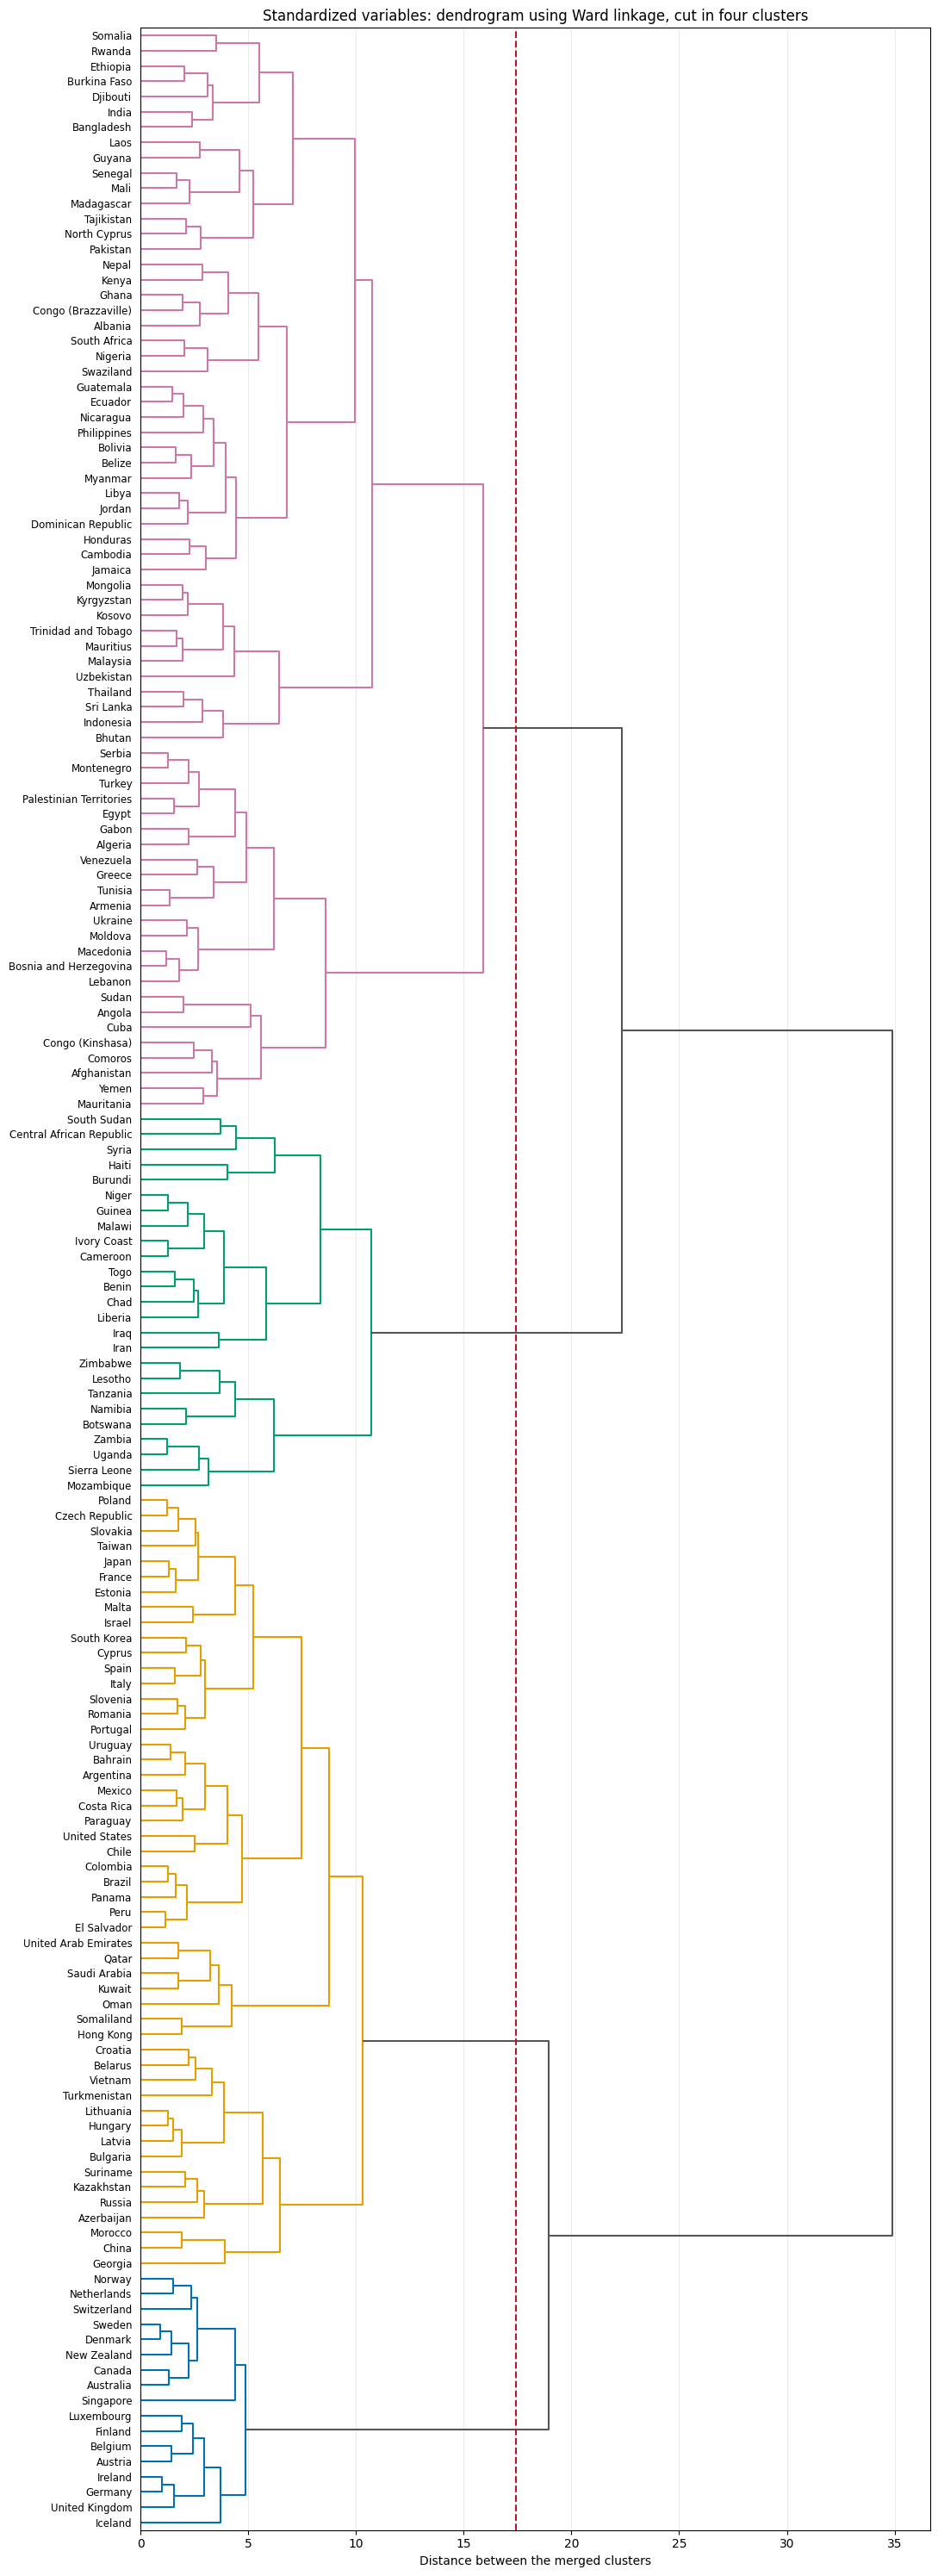

In [9]:
data_standard = pd.DataFrame(StandardScaler().fit_transform(data), columns=data.columns)

Z_standard = shc.linkage(data_standard, method='ward')

fig, ax = plt.subplots(figsize=(11, 30))
plot_dendrogram(ax, Z_standard, n_clusters, 'Standardized variables: dendrogram using Ward linkage, cut in four clusters',
                labels=country_names, font_size=8.5)
plt.tight_layout()

In [10]:
cluster_labels_standard = ordered_clusters(Z_standard, n_clusters)

pd.crosstab(pd.Series(cluster_labels, name='Rows normalized'),
            pd.Series(cluster_labels_standard, name='Columns standardized'))

Columns standardized,0,1,2,3
Rows normalized,,,,
0,17,7,0,2
1,0,35,0,24
2,0,9,0,37
3,0,0,25,8


The two partitions are related, but they are not the same.

### Profile of the clusters

Means of the standardized variables in each cluster: positive (red) is above the average of all the countries, negative (blue) below.

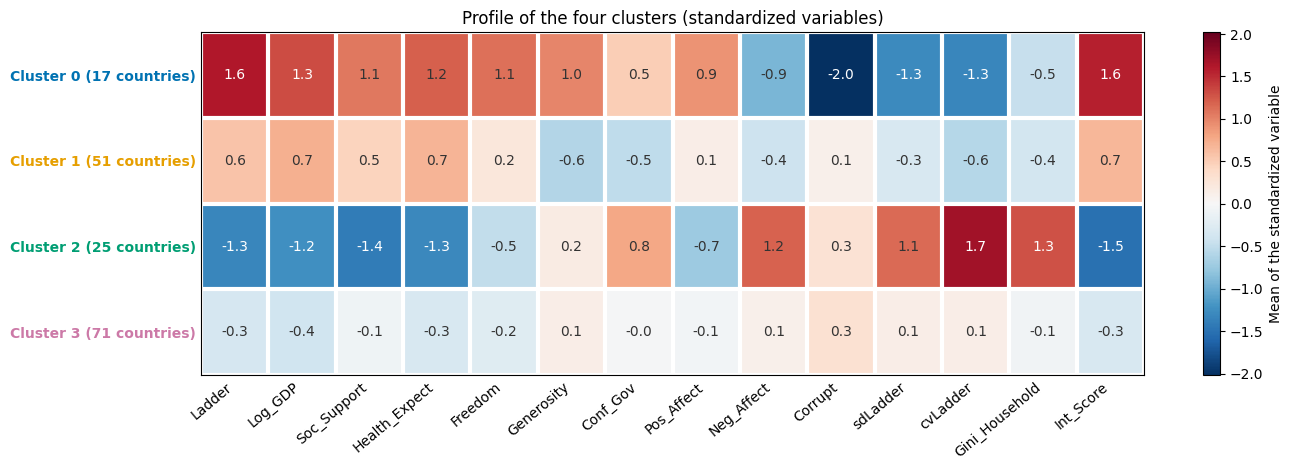

In [11]:
profiles_standard = data_standard.groupby(cluster_labels_standard).mean()
sizes = pd.Series(cluster_labels_standard).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(14, 4.8))
limit = np.abs(profiles_standard.to_numpy()).max()
im = ax.imshow(profiles_standard, cmap='RdBu_r', vmin=-limit, vmax=limit, aspect='auto')
for i in range(profiles_standard.shape[0]):
    for j in range(profiles_standard.shape[1]):
        value = profiles_standard.iloc[i, j]
        ax.text(j, i, f'{value:.1f}', ha='center', va='center', fontsize=10,
                color='white' if abs(value) > 0.6*limit else '#333333')
ax.set_xticks(range(data.shape[1]), data.columns, rotation=40, ha='right')
ax.set_yticks(range(n_clusters), [f'Cluster {c} ({sizes[c]} countries)' for c in range(n_clusters)])
for tick, c in zip(ax.get_yticklabels(), range(n_clusters)):
    tick.set_color(palette[c])
    tick.set_fontweight('bold')
ax.set_xticks(np.arange(data.shape[1]+1)-0.5, minor=True)
ax.set_yticks(np.arange(n_clusters+1)-0.5, minor=True)
ax.grid(which='minor', color='white', linewidth=3)
ax.tick_params(which='both', length=0)
fig.colorbar(im, ax=ax, label='Mean of the standardized variable')
ax.set_title('Profile of the four clusters (standardized variables)')
plt.tight_layout()

### The countries in the first two principal components

To see the clusters we project the standardized data on their first two principal components, and label some countries.

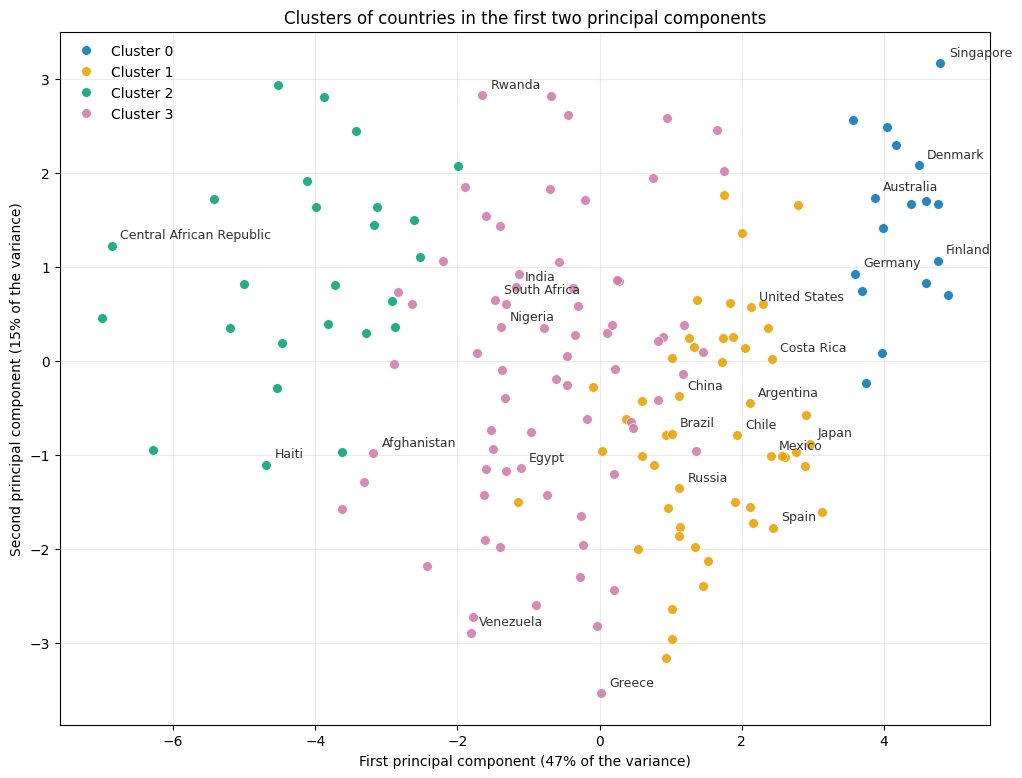

In [12]:
pca = PCA(n_components=2)
scores = pca.fit_transform(data_standard)

some_countries = ['Mexico', 'United States', 'Finland', 'Denmark', 'Japan', 'China', 'India', 'Brazil', 'Germany',
                  'Spain', 'Russia', 'Afghanistan', 'Nigeria', 'South Africa', 'Argentina', 'Costa Rica', 'Singapore',
                  'Rwanda', 'Haiti', 'Greece', 'Egypt', 'Australia', 'Chile', 'Venezuela', 'Central African Republic']

fig, ax = plt.subplots(figsize=(12, 9))
for c in range(n_clusters):
    rows = cluster_labels_standard == c
    ax.plot(scores[rows, 0], scores[rows, 1], 'o', color=palette[c], markersize=7, markeredgecolor='white',
            markeredgewidth=0.5, alpha=0.85, label=f'Cluster {c}')
for name in some_countries:
    if name in country_names:
        i = country_names.index(name)
        ax.annotate(name, scores[i], xytext=(6, 5), textcoords='offset points', fontsize=9, color='#333333')
ax.set_xlabel(f'First principal component ({100*pca.explained_variance_ratio_[0]:.0f}% of the variance)')
ax.set_ylabel(f'Second principal component ({100*pca.explained_variance_ratio_[1]:.0f}% of the variance)')
ax.set_title('Clusters of countries in the first two principal components')
ax.legend(loc='best', frameon=False)
ax.grid(True, alpha=0.25)